In [8]:
%pip install pandas numpy openpyxl requests sqlalchemy scikit-learn xgboost matplotlib seaborn fastapi uvicorn joblib pytest httpx shap timezone

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement timezone (from versions: none)
ERROR: No matching distribution found for timezone


In [1]:
from pathlib import Path
import requests

DATA_DIR = Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

DATA_URL = "https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip"
ZIP_PATH = DATA_DIR / "online_retail_ii.zip"

if not ZIP_PATH.exists():
    response = requests.get(DATA_URL, timeout=120)
    response.raise_for_status()
    ZIP_PATH.write_bytes(response.content)

print("Dataset downloaded:", ZIP_PATH.resolve())
print("File size (MB):", round(ZIP_PATH.stat().st_size / (1024 * 1024), 2))

Dataset downloaded: C:\Users\DELL XPS\Downloads\technical_one\data\online_retail_ii.zip
File size (MB): 43.51


In [2]:
import zipfile

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    print(archive.namelist())
    archive.extractall(DATA_DIR)

print("Extraction completed.")

['online_retail_II.xlsx']
Extraction completed.


In [3]:
import pandas as pd
from pathlib import Path

excel_files = list(DATA_DIR.rglob("*.xlsx"))

if not excel_files:
    raise FileNotFoundError(
        "No Excel workbook found. Check the dataset download and extraction."
    )

DATA_FILE = excel_files[0]

df = pd.read_excel(DATA_FILE, sheet_name=0)

print("Dataset shape:", df.shape)
display(df.head())
display(df.info())

Dataset shape: (525461, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


<class 'pandas.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[us]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 32.1+ MB


None

data quality report

In [4]:
import sqlite3
DB_PATH = Path("database/retail_ai.db")
DB_PATH.parent.mkdir(parents=True, exist_ok=True)

conn = sqlite3.connect(DB_PATH)

df.to_sql(
    "retail_raw",
    conn,
    if_exists="replace",
    index=False
)

print("Database:", DB_PATH.resolve())

stored_df = pd.read_sql_query(
    "SELECT * FROM retail_raw LIMIT 5",
    conn
)

display(stored_df)

Database: C:\Users\DELL XPS\Downloads\technical_one\database\retail_ai.db


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [5]:
issues = []

def add_issue(check, count, details=""):
    issues.append({
        "check": check,
        "issue_count": int(count),
        "details": details
    })

# Missing values
for col in df.columns:
    count = df[col].isna().sum()
    if count:
        add_issue("missing_values", count, col)

# Duplicate complete rows
add_issue(
    "duplicate_rows",
    df.duplicated().sum(),
    "Exact duplicate records"
)

# Duplicate column names
add_issue(
    "duplicate_column_names",
    df.columns.duplicated().sum(),
    "Column names repeated after standardization"
)

# Identify common retail columns
quantity_col = next(
    (c for c in ["quantity", "qty"] if c in df.columns), None
)
price_col = next(
    (c for c in ["unit_price", "price", "unitprice"] if c in df.columns), None
)
date_col = next(
    (c for c in ["invoicedate", "invoice_date", "order_date",
                 "transaction_date", "date"] if c in df.columns), None
)

if quantity_col:
    quantity = pd.to_numeric(df[quantity_col], errors="coerce")
    add_issue(
        "invalid_quantity",
        (quantity.isna() | (quantity <= 0)).sum(),
        quantity_col
    )

if price_col:
    price = pd.to_numeric(df[price_col], errors="coerce")
    add_issue(
        "invalid_price",
        (price.isna() | (price < 0)).sum(),
        price_col
    )

if date_col:
    parsed_dates = pd.to_datetime(df[date_col], errors="coerce")
    add_issue(
        "invalid_dates",
        parsed_dates.isna().sum(),
        date_col
    )

quality_report = pd.DataFrame(
    issues,
    columns=["check", "issue_count", "details"]
)

display(quality_report)

,check,issue_count,details
0,missing_values,2928,Description
1,missing_values,107927,Customer ID
2,duplicate_rows,6865,Exact duplicate records
3,duplicate_column_names,0,Column names repeated after standardization


In [6]:
from datetime import datetime,timezone
quality_report["checked_at"] = datetime.now(
    timezone.utc
).isoformat()

quality_report.to_sql(
    "data_quality_report",
    conn,
    if_exists="replace",
    index=False
)

REPORT_PATH = Path("reports")
REPORT_PATH.mkdir(parents=True, exist_ok=True)

quality_report.to_csv(
    REPORT_PATH / "data_quality_report.csv",
    index=False
)

print("Quality report saved to SQLite and CSV.")
display(
    pd.read_sql_query(
        "SELECT * FROM data_quality_report",
        conn
    )
)

Quality report saved to SQLite and CSV.


,check,issue_count,details,checked_at
0,missing_values,2928,Description,2026-10-28T13:25:39.957624+00:00
1,missing_values,107927,Customer ID,2026-10-28T13:25:39.957624+00:00
2,duplicate_rows,6865,Exact duplicate records,2026-10-28T13:25:39.957624+00:00
3,duplicate_column_names,0,Column names repeated after standardization,2026-10-28T13:25:39.957624+00:00


In [10]:
tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table'",
    conn
)

print("SQLite tables:")
display(tables)

print("Raw record count:")
display(
    pd.read_sql_query(
        "SELECT COUNT(*) AS total_rows FROM retail_raw",
        conn
    )
)

conn.close()

SQLite tables:


,name
0,retail_raw
1,data_quality_report


Raw record count:


,total_rows
0,525461


In [7]:
print(df.isnull().sum())
df.shape

Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107927
Country             0
dtype: int64


(525461, 8)

In [8]:
import pandas as pd
import numpy as np

clean_df = df.copy()

# Detect exact duplicate rows
duplicate_count = clean_df.duplicated().sum()

# Identify available columns
quantity_col = next(
    (c for c in ["quantity", "qty"] if c in clean_df.columns), None
)

price_col = next(
    (c for c in ["unit_price", "price", "unitprice"]
     if c in clean_df.columns), None
)

date_col = next(
    (c for c in ["invoicedate", "invoice_date", "order_date",
                 "transaction_date", "date"]
     if c in clean_df.columns), None
)

print("Exact duplicate rows:", duplicate_count)
print("Quantity column:", quantity_col)
print("Price column:", price_col)
print("Date column:", date_col)

if quantity_col:
    clean_df[quantity_col] = pd.to_numeric(
        clean_df[quantity_col], errors="coerce"
    )
    print("Missing or invalid quantities:",
          clean_df[quantity_col].isna().sum())
    print("Negative quantities (possible returns):",
          (clean_df[quantity_col] < 0).sum())
    print("Zero quantities:",
          (clean_df[quantity_col] == 0).sum())

if price_col:
    clean_df[price_col] = pd.to_numeric(
        clean_df[price_col], errors="coerce"
    )
    print("Negative prices:",
          (clean_df[price_col] < 0).sum())

if date_col:
    clean_df[date_col] = pd.to_datetime(
        clean_df[date_col], errors="coerce"
    )
    print("Invalid dates:", clean_df[date_col].isna().sum())

Exact duplicate rows: 6865
Quantity column: None
Price column: None
Date column: None


In [9]:
if quantity_col:
    returns_df = clean_df[clean_df[quantity_col] < 0].copy()
    zero_quantity_df = clean_df[clean_df[quantity_col] == 0].copy()

    print("Potential return records:", len(returns_df))
    print("Zero-quantity records:", len(zero_quantity_df))

if "invoiceno" in clean_df.columns:
    clean_df["is_cancellation"] = (
        clean_df["invoiceno"]
        .astype("string")
        .str.startswith("C", na=False)
    )
elif "invoice_no" in clean_df.columns:
    clean_df["is_cancellation"] = (
        clean_df["invoice_no"]
        .astype("string")
        .str.startswith("C", na=False)
    )
else:
    clean_df["is_cancellation"] = False

print("Potential cancellation records:",
      clean_df["is_cancellation"].sum())

Potential cancellation records: 0


In [10]:
clean_df = clean_df.drop_duplicates().copy()

if date_col:
    clean_df = clean_df[clean_df[date_col].notna()].copy()

print("Original rows:", len(df))
print("Rows after initial cleaning:", len(clean_df))
print("Rows removed:", len(df) - len(clean_df))

Original rows: 525461
Rows after initial cleaning: 518596
Rows removed: 6865


In [11]:
import sqlite3
from pathlib import Path

DB_PATH = Path("database/retail_ai.db")
DB_PATH.parent.mkdir(parents=True, exist_ok=True)

conn = sqlite3.connect(DB_PATH)

clean_df.to_sql(
    "retail_cleaned",
    conn,
    if_exists="replace",
    index=False
)

print("Cleaned data saved to:", DB_PATH.resolve())

display(pd.read_sql_query(
    "SELECT COUNT(*) AS cleaned_rows FROM retail_cleaned",
    conn
))

Cleaned data saved to: C:\Users\DELL XPS\Downloads\technical_one\database\retail_ai.db


,cleaned_rows
0,518596


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_eda = clean_df.copy()

def find_col(options):
    return next((c for c in options if c in df_eda.columns), None)

date_col = find_col([
    "InvoiceDate"
])

quantity_col = find_col(["Quantity"])
price_col = find_col([ "Price"])
product_col = find_col([
    "Description"
])
customer_col = find_col([ "Customer_ID"])
country_col = find_col(["country"])

if date_col is None or quantity_col is None or price_col is None:
    raise ValueError(
        "Required date, quantity, or price column not found. "
        f"Available columns: {df_eda.columns.tolist()}"
    )

df_eda[date_col] = pd.to_datetime(df_eda[date_col], errors="coerce")
df_eda[quantity_col] = pd.to_numeric(df_eda[quantity_col], errors="coerce")
df_eda[price_col] = pd.to_numeric(df_eda[price_col], errors="coerce")

df_eda["line_value"] = df_eda[quantity_col] * df_eda[price_col]

print("Date column:", date_col)
print("Product column:", product_col)
print("Customer column:", customer_col)
print("Rows available:", len(df_eda))

Date column: InvoiceDate
Product column: Description
Customer column: None
Rows available: 518596


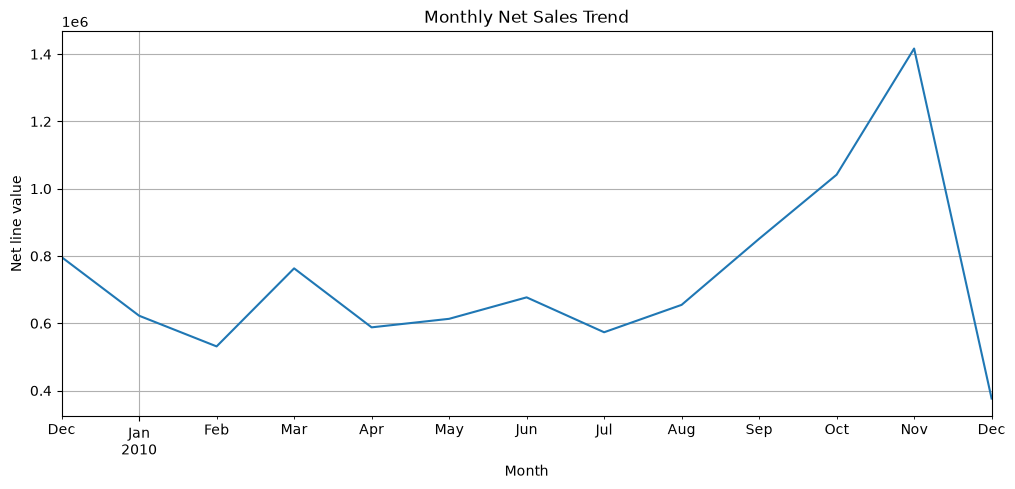

In [15]:
import matplotlib.pyplot as plt
monthly_sales = (
    df_eda.dropna(subset=[date_col])
    .set_index(date_col)["line_value"]
    .resample("MS")
    .sum()
)

plt.figure(figsize=(12, 5))
monthly_sales.plot()
plt.title("Monthly Net Sales Trend")
plt.xlabel("Month")
plt.ylabel("Net line value")
plt.grid(True)
plt.show()

,net_line_value
Description,
REGENCY CAKESTAND 3 TIER,162885.71
WHITE HANGING HEART T-LIGHT HOLDER,157580.28
DOTCOM POSTAGE,116401.99
ASSORTED COLOUR BIRD ORNAMENT,72251.32
PAPER CHAIN KIT 50'S CHRISTMAS,57808.25
JUMBO BAG RED RETROSPOT,56329.56
PARTY BUNTING,49626.92
ROTATING SILVER ANGELS T-LIGHT HLDR,47641.89
POSTAGE,46092.36


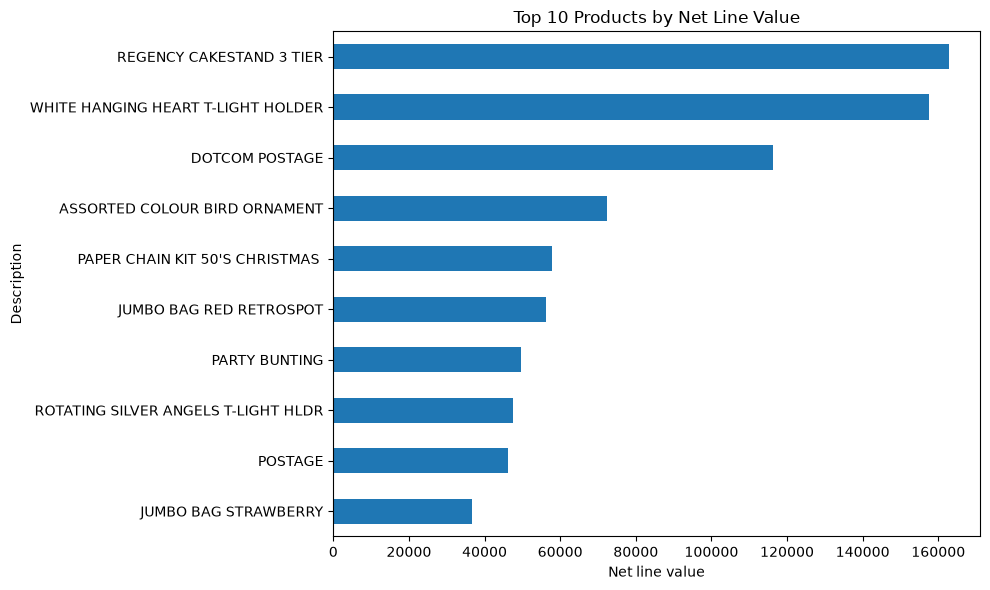

In [16]:
if product_col:
    top_products = (
        df_eda.groupby(product_col)["line_value"]
        .sum()
        .sort_values(ascending=False)
        .head(10)
    )

    display(top_products.to_frame("net_line_value"))

    top_products.sort_values().plot(
        kind="barh", figsize=(10, 6)
    )
    plt.title("Top 10 Products by Net Line Value")
    plt.xlabel("Net line value")
    plt.tight_layout()
    plt.show()
else:
    print("No product identifier or description column was found.")

In [17]:
if customer_col:
    customer_summary = (
        df_eda.dropna(subset=[customer_col])
        .groupby(customer_col)
        .agg(
            total_line_value=("line_value", "sum"),
            total_items=(quantity_col, "sum"),
            purchase_lines=(quantity_col, "size")
        )
        .sort_values("total_line_value", ascending=False)
    )

    print("Unique customers:", df_eda[customer_col].nunique())
    display(customer_summary.head(10))
else:
    print("No customer identifier is available.")

No customer identifier is available.


In [18]:
if quantity_col:
    print("Negative-quantity lines:",
          (df_eda[quantity_col] < 0).sum())

if "is_cancellation" in df_eda.columns:
    print("Potential cancellation lines:",
          df_eda["is_cancellation"].sum())

if customer_col:
    return_summary = (
        df_eda[df_eda[quantity_col] < 0]
        .groupby(customer_col)
        .size()
        .sort_values(ascending=False)
        .head(10)
    )
    print("Customers with the most return lines:")
    display(return_summary.to_frame("return_lines"))

Negative-quantity lines: 12302
Potential cancellation lines: 0


In [19]:
conn = sqlite3.connect("database/retail_ai.db")

monthly_sales.rename("net_line_value").to_frame().to_sql(
    "monthly_sales_eda", conn, if_exists="replace"
)

if customer_col:
    customer_summary.to_sql(
        "customer_summary_eda", conn, if_exists="replace"
    )

print("EDA summaries saved to SQLite.")
conn.close()

EDA summaries saved to SQLite.


In [20]:
import pandas as pd
import numpy as np

df_features = clean_df.copy()

print(df_features.columns.tolist())

['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'is_cancellation']


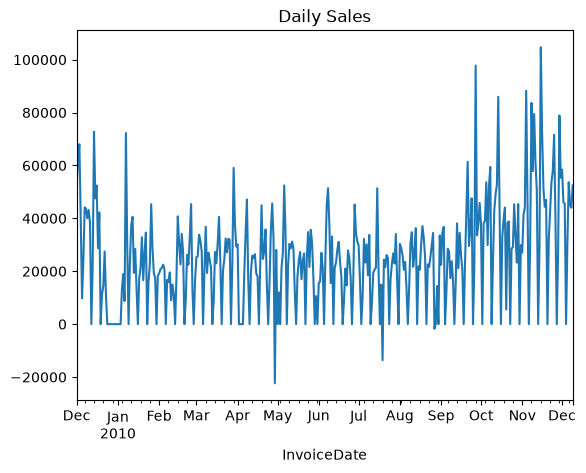

In [23]:
df_features["line_value"] = (
    df_features["Quantity"] * df_features["Price"]
)

df_features["invoicedate"] = pd.to_datetime(
    df_features["InvoiceDate"]
)

daily_sales = df_features.set_index(
    "InvoiceDate"
)["line_value"].resample("D").sum()

daily_sales.plot(title="Daily Sales")
plt.show()

In [24]:
features = pd.DataFrame({"sales": daily_sales})

features["lag_1"] = features["sales"].shift(1)
features["lag_7"] = features["sales"].shift(7)
features["month"] = features.index.month
features["day_of_week"] = features.index.dayofweek

features = features.dropna()

display(features.head())

C:\Users\DELL XPS\AppData\Local\Temp\ipykernel_13020\1157596648.py:6: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  features["day_of_week"] = features.index.dayofweek


,sales,lag_1,lag_7,month,day_of_week
InvoiceDate,,,,,
2009-12-08,43702.14,44169.88,53010.76,12,1
2009-12-09,40046.12,43702.14,62583.66,12,2
2009-12-10,43134.33,40046.12,68027.59,12,3
2009-12-11,38213.21,43134.33,40195.80,12,4
2009-12-12,0.00,38213.21,9803.05,12,5


In [26]:
import pandas as pd

cols = ["Quantity", "Price"]

for col in cols:
    Q1 = clean_df[col].quantile(0.25)
    Q3 = clean_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = clean_df[
        (clean_df[col] < lower) |
        (clean_df[col] > upper)
    ]

    print(f"{col}: {len(outliers)} outliers")
    print("Lower bound:", lower)
    print("Upper bound:", upper)

Quantity: 57744 outliers
Lower bound: -12.5
Upper bound: 23.5
Price: 35078 outliers
Lower bound: -3.1899999999999995
Upper bound: 8.649999999999999


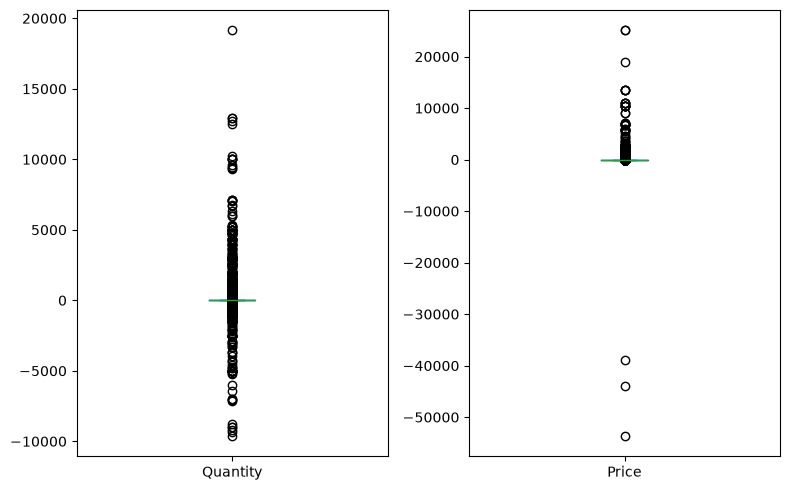

In [27]:
import matplotlib.pyplot as plt

clean_df[["Quantity", "Price"]].plot(
    kind="box",
    subplots=True,
    figsize=(8, 5)
)

plt.tight_layout()
plt.show()

In [28]:
import pandas as pd
import numpy as np

df = clean_df.copy()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

df["sales"] = df["Quantity"] * df["Price"]

daily = df.set_index("InvoiceDate")["sales"].resample("D").sum()

display(daily.head())

InvoiceDate
2009-12-01    53010.76
2009-12-02    62583.66
2009-12-03    68027.59
2009-12-04    40195.80
2009-12-05     9803.05
Freq: D, Name: sales, dtype: float64

In [29]:
data = pd.DataFrame({"sales": daily})

data["lag7"] = data["sales"].shift(7)
data["lag14"] = data["sales"].shift(14)
data["day"] = data.index.dayofweek
data["month"] = data.index.month

data = data.dropna()

C:\Users\DELL XPS\AppData\Local\Temp\ipykernel_13020\772505662.py:5: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  data["day"] = data.index.dayofweek


In [30]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

X = data[["lag7", "lag14", "day", "month"]]
y = data["sales"]

split = int(len(data) * 0.8)

X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

model = XGBRegressor(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.05,
    random_state=42
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

In [31]:
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

wape = (
    np.abs(y_test - predictions).sum()
    / np.abs(y_test).sum()
    * 100
    if np.abs(y_test).sum() != 0 else np.nan
)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("WAPE (%):", round(wape, 2))

MAE: 15178.02
RMSE: 21124.52
WAPE (%): 37.45


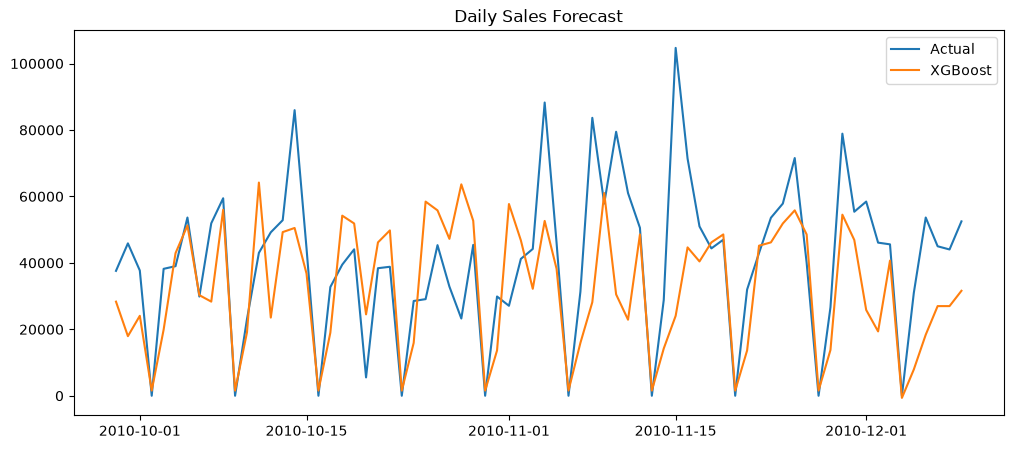

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(y_test.index, y_test, label="Actual")
plt.plot(y_test.index, predictions, label="XGBoost")
plt.title("Daily Sales Forecast")
plt.legend()
plt.show()

In [33]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Predict using sales from 7 days earlier
baseline = daily.shift(7).reindex(y_test.index)

# Compare on identical test dates
actual = y_test.loc[baseline.dropna().index]
baseline = baseline.dropna()

mae_base = mean_absolute_error(actual, baseline)
rmse_base = np.sqrt(mean_squared_error(actual, baseline))
wape_base = (
    np.abs(actual - baseline).sum() / np.abs(actual).sum() * 100
    if np.abs(actual).sum() != 0 else np.nan
)

print("Seasonal Naive Baseline")
print("MAE:", round(mae_base, 2))
print("RMSE:", round(rmse_base, 2))
print("WAPE:", round(wape_base, 2), "%")

Seasonal Naive Baseline
MAE: 14022.71
RMSE: 21266.28
WAPE: 34.6 %


In [34]:
results = pd.DataFrame({
    "Model": ["Seasonal Naive", "XGBoost"],
    "MAE": [
        mae_base,
        mean_absolute_error(actual, predictions[
            y_test.index.get_indexer(actual.index)
        ])
    ],
    "RMSE": [
        rmse_base,
        np.sqrt(mean_squared_error(
            actual,
            predictions[y_test.index.get_indexer(actual.index)]
        ))
    ]
})

display(results)

,Model,MAE,RMSE
0,Seasonal Naive,14022.712194,21266.282415
1,XGBoost,15178.021357,21124.521280


In [35]:
results = pd.DataFrame({
    "Model": ["Seasonal Naive", "XGBoost"],
    "MAE": [mae_base, mae],
    "RMSE": [rmse_base, rmse]
})

display(results)

,Model,MAE,RMSE
0,Seasonal Naive,14022.712194,21266.282415
1,XGBoost,15178.021357,21124.521280


In [36]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

baseline = daily.shift(7).reindex(y_test.index)
actual = y_test.loc[baseline.dropna().index]
base_pred = baseline.dropna()

xgb_pred = pd.Series(predictions, index=y_test.index).loc[actual.index]

results = pd.DataFrame({
    "Model": ["Seasonal Naive", "XGBoost"],
    "MAE": [
        mean_absolute_error(actual, base_pred),
        mean_absolute_error(actual, xgb_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(actual, base_pred)),
        np.sqrt(mean_squared_error(actual, xgb_pred))
    ],
    "WAPE (%)": [
        np.abs(actual - base_pred).sum() / np.abs(actual).sum() * 100,
        np.abs(actual - xgb_pred).sum() / np.abs(actual).sum() * 100
    ]
})

display(results.round(2))

,Model,MAE,RMSE,WAPE (%)
0,Seasonal Naive,14022.71,21266.28,34.60
1,XGBoost,15178.02,21124.52,37.45


In [37]:
results = pd.DataFrame({
    "Model": ["Seasonal Naive", "XGBoost"],
    "WAPE (%)": [34.60, 37.45]
})

display(results)

best_model = results.loc[results["WAPE (%)"].idxmin(), "Model"]
print("Best model:", best_model)

,Model,WAPE (%)
0,Seasonal Naive,34.60
1,XGBoost,37.45


Best model: Seasonal Naive


In [38]:
print(clean_df.columns.tolist())
clean_df.head(3)

['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'is_cancellation']


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,is_cancellation
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False


In [39]:
import pandas as pd

df = clean_df.copy()

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["Sales"] = df["Quantity"] * df["Price"]

customers = df.groupby("Customer ID").agg(
    last_purchase=("InvoiceDate", "max"),
    total_orders=("Invoice", "nunique"),
    total_spent=("Sales", "sum"),
    total_quantity=("Quantity", "sum")
).reset_index()

print(customers.head())
print("Total customers:", len(customers))

   Customer ID       last_purchase  total_orders  total_spent  total_quantity
0      12346.0 2010-10-04 16:33:00            15       -51.74              53
1      12347.0 2010-12-07 14:57:00             2      1323.32             828
2      12348.0 2010-09-27 14:59:00             1       222.16             373
3      12349.0 2010-10-28 08:23:00             4      2646.99             988
4      12351.0 2010-11-29 15:23:00             1       300.93             261
Total customers: 4383


In [40]:
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

customers["days_inactive"] = (
    reference_date - customers["last_purchase"]
).dt.days

customers["churn"] = (
    customers["days_inactive"] > 90
).astype(int)

print(customers["churn"].value_counts())

churn
0    2925
1    1458
Name: count, dtype: int64


In [41]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

X = customers[[
    "total_orders", "total_spent", "total_quantity", "days_inactive"
]]
y = customers["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = RandomForestClassifier(
    n_estimators=100, random_state=42, class_weight="balanced"
)
model.fit(X_train, y_train)

pred = model.predict(X_test)

print(classification_report(y_test, pred, zero_division=0))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       585
           1       1.00      1.00      1.00       292

    accuracy                           1.00       877
   macro avg       1.00      1.00      1.00       877
weighted avg       1.00      1.00      1.00       877



In [42]:
import sqlite3

conn = sqlite3.connect("retail_ai.db")
customers.to_sql("customer_churn", conn, if_exists="replace", index=False)
conn.close()

print("Customer churn data saved!")

Customer churn data saved!


In [43]:
from sklearn.ensemble import IsolationForest

df = clean_df.copy()
df["transaction_value"] = df["Quantity"] * df["Price"]

features = df[["Quantity", "Price", "transaction_value"]].fillna(0)

model_anomaly = IsolationForest(
    contamination=0.02, random_state=42
)

df["anomaly"] = model_anomaly.fit_predict(features)
df["anomaly"] = df["anomaly"].map({1: "Normal", -1: "Unusual"})

print(df["anomaly"].value_counts())
display(df[df["anomaly"] == "Unusual"].head(10))

anomaly
Normal     508250
Unusual     10346
Name: count, dtype: int64


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,is_cancellation,transaction_value,anomaly
67,489438,85132A,CHARLIE + LOLA BISCUITS TINS,60,2009-12-01 09:24:00,6.38,18102.0,United Kingdom,False,382.80,Unusual
68,489438,85132C,CHARLIE AND LOLA FIGURES TINS,60,2009-12-01 09:24:00,6.40,18102.0,United Kingdom,False,384.00,Unusual
95,489441,22111,SCOTTIE DOG HOT WATER BOTTLE,48,2009-12-01 09:44:00,4.25,18087.0,United Kingdom,False,204.00,Unusual
126,489444,POST,POSTAGE,1,2009-12-01 09:55:00,141.00,12636.0,USA,False,141.00,Unusual
173,489447,POST,POSTAGE,1,2009-12-01 10:10:00,130.00,12362.0,Belgium,False,130.00,Unusual
176,489448,20823,GOLD WINE GOBLET,48,2009-12-01 10:18:00,4.25,15413.0,United Kingdom,False,204.00,Unusual
217,489460,84598,BOYS ALPHABET IRON ON PATCHES,576,2009-12-01 10:46:00,0.21,16167.0,United Kingdom,False,120.96,Unusual
223,489460,84568,GIRLS ALPHABET IRON ON PATCHES,288,2009-12-01 10:46:00,0.21,16167.0,United Kingdom,False,60.48,Unusual
282,489465,84879,ASSORTED COLOUR BIRD ORNAMENT,160,2009-12-01 10:52:00,1.45,13767.0,United Kingdom,False,232.00,Unusual
575,489523,84879,ASSORTED COLOUR BIRD ORNAMENT,800,2009-12-01 11:46:00,1.45,12931.0,United Kingdom,False,1160.00,Unusual


In [44]:
conn = sqlite3.connect("retail_ai.db")
df.to_sql("transaction_anomalies", conn, if_exists="replace", index=False)
conn.close()

print("Anomaly results saved!")

Anomaly results saved!


In [48]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

features = ["total_orders", "total_spent", "total_quantity"]
X = customers[features].fillna(0)
y = customers["churn"]

if y.nunique() < 2:
    raise ValueError("Churn data must contain both classes.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

churn_model = RandomForestClassifier(
    n_estimators=100, random_state=42,
    class_weight="balanced"
)
churn_model.fit(X_train, y_train)

pred = churn_model.predict(X_test)
prob = churn_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, pred, zero_division=0))
print("ROC-AUC:", round(roc_auc_score(y_test, prob), 3))

              precision    recall  f1-score   support

           0       0.77      0.70      0.74       585
           1       0.50      0.59      0.54       292

    accuracy                           0.66       877
   macro avg       0.64      0.65      0.64       877
weighted avg       0.68      0.66      0.67       877

ROC-AUC: 0.706


In [49]:
from joblib import dump

dump(churn_model, "churn_model.joblib")
print("Model saved.")

Model saved.
